# 37 · Does angular agreement add to a stronger encoder?

Compare standard ResNet-50 V1 preprocessing with the earlier 56 × 56 full-frame run. Then test a single fixed combination with local Q. The fusion averages two within-gallery ranks with equal weights. Neither method uses CIFAR-10 labels to fit scores.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'observables').is_dir())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
R = ROOT/'results'/'stage11'
import json
from observables.stage6 import CONDITIONS
from observables.stage11 import FUSION_METHODS


## 1. Verify the held-out panel

The fresh RGB panel excludes all previous 480 CIFAR-10 sources and exact pixel duplicates. The checkpoint hash is fixed across the old run and both new preprocessing pipelines. The standard transform changes both spatial sampling and cropping.

In [3]:
fresh = pd.read_csv(R/'fresh_membership.csv')
audit = pd.read_csv(R/'audit_membership.csv')
assert fresh.source.nunique() == audit.source.nunique() == 480
assert set(fresh.source).isdisjoint(audit.source)
assert fresh.groupby(['gallery','label']).size().eq(4).all()
meta = {size: json.loads((R/f'encoder_{size}.json').read_text()) for size in (56,224)}
prior = json.loads((ROOT/'results'/'stage10'/'cifar10'/'frozen_manifest.json').read_text())
assert meta[56]['checkpoint_sha256'] == meta[224]['checkpoint_sha256'] == prior['models']['ResNet-50']['sha256']
assert meta[56]['test_sha256'] == meta[224]['test_sha256']
display(pd.DataFrame(meta).T[['size','resize','device','torch','torchvision']])


,size,resize,device,torch,torchvision
56,56,[56],cpu,2.5.1,0.20.1
224,224,[256],cpu,2.5.1,0.20.1


## 2. Top-1, mean average precision, and paired effects

The transformed panel is primary. The top-1 estimate gives fractional credit for ties. AP averages precision at the three true match ranks, with exact score ties averaged over their possible orders. Chance top-1 is 3/39. The intervals pair the same 12 galleries across methods.

In [5]:
summary = pd.read_csv(R/'summary.csv').query('panel == "fresh"')
scores = summary.pivot(index='method', columns='split', values=['top1','ap'])
display((100*scores.reindex(FUSION_METHODS)).round(2))
effects = pd.read_csv(R/'contrasts.csv').query('panel == "fresh"')
cols = ['delta','low95','high95']
display((100*effects.set_index(['split','metric','left','right'])[cols]).round(2))


top1                 ap            
split                clean transformed  clean transformed
method                                                   
encoder 56           33.96       21.48  37.00       27.63
encoder 224          46.67       32.14  47.33       35.79
magnitude            15.83       11.30  20.87       18.68
phase                20.00       14.87  24.52       21.71
encoder 224 + phase  37.33       26.30  37.44       30.57

delta  low95  high95
split       metric left                right                            
clean       top1   encoder 224 + phase encoder 224  -9.34 -14.93   -4.03
                   encoder 224         encoder 56   12.71   7.92   17.08
                   phase               magnitude     4.17   1.04    7.29
            ap     encoder 224 + phase encoder 224  -9.89 -11.50   -8.34
                   encoder 224         encoder 56   10.33   8.62   12.09
                   phase               magnitude     3.66   2.34    4.73
transformed top1   encoder 224 + phase encoder 224  -5.84  -8.09   -3.56
                   encoder 224         encoder 56   10.65   8.49   12.50
                   phase               magnitude     3.57   1.85    5.26
            ap     encoder 224 + phase encoder 224  -5.23  -6.08   -4.35
                   encoder 224         encoder 56    8.17   7.05    9.26
                   phase               magnitude     3.04   1.68    4.09

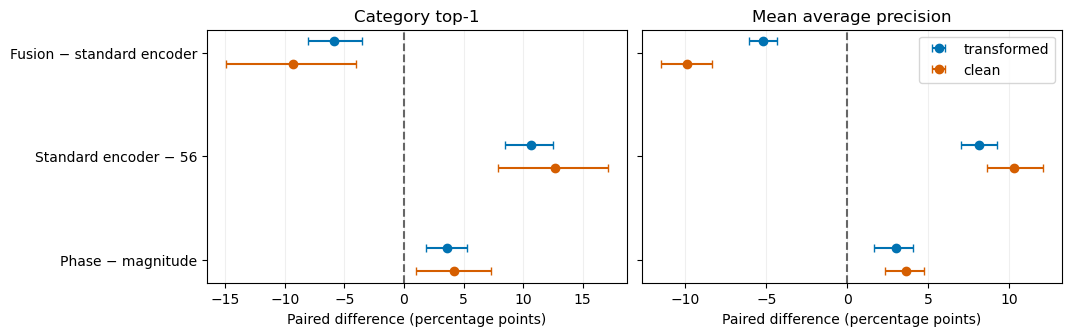

In [7]:
pairs = [('encoder 224 + phase','encoder 224'), ('encoder 224','encoder 56'), ('phase','magnitude')]
names = ['Fusion − standard encoder','Standard encoder − 56','Phase − magnitude']
fig, axes = plt.subplots(1,2, figsize=(10.6, 3.25), sharey=True, layout='constrained')
pos = np.arange(len(names))
for ax, metric, title in zip(axes, ['top1','ap'], ['Category top-1','Mean average precision']):
    for split, offset, color in [('transformed',-.11,'#0072b2'), ('clean',.11,'#d55e00')]:
        e = effects.query('metric == @metric and split == @split').set_index(['left','right']).loc[pairs]
        d, lo, hi = (100*e[c].to_numpy() for c in cols)
        ax.errorbar(d, pos+offset, xerr=[d-lo, hi-d], fmt='o', color=color, capsize=3, label=split)
    ax.axvline(0, color='0.4', ls='--')
    ax.set(title=title, xlabel='Paired difference (percentage points)', yticks=pos, yticklabels=names)
    ax.grid(axis='x', alpha=.2)
axes[0].invert_yaxis()
axes[1].legend()
fig.savefig(R/'37_fusion_contrasts.png', dpi=165)
plt.show()


## 3. Check the effect by corruption

These point estimates are descriptive. Every method sees the same transformed image. The 224 crop can discard boundary content that the 56 full-frame run preserves.

In [9]:
d = pd.read_csv(R/'condition_summary.csv').query('panel == "fresh"').pivot(
    index='condition', columns='method', values=['top1','ap']).reindex(CONDITIONS)
focus = pd.DataFrame({f'{metric} fusion minus encoder': 100*(d[(metric,'encoder 224 + phase')]-
                      d[(metric,'encoder 224')]) for metric in ['top1','ap']})
display(focus.round(2))


,top1 fusion minus encoder,ap fusion minus encoder
condition,,
clean,-9.34,-9.89
shift,-8.07,-9.05
gain,-7.99,-7.39
noise,1.42,-0.04
blur,-2.05,-2.11
rotation,-7.85,-5.81
crop,-10.38,-8.66
occlusion,-10.90,-7.87
shift + noise,-0.90,-0.87
